# 05 · Decoding, watched: lookup → matching → BP+OSD (all written by us)

**What this notebook is for.** Every decoder here is ours (`qdec/decoders.py`), and every one is checked against the established tool on the same shots:
PyMatching for matching and `ldpc` for BP+OSD. They're only used as referees.

| decoder | needs | idea |
|---|---|---|
| lookup | tiny problems | try every fault set by weight, remember the best per syndrome |
| MWPM | a graph (surface, toric) | shortest paths + exact minimum-weight pairing |
| BP+OSD | any H, including hypergraphs (gross) | BP's beliefs, then solve exactly on the most reliable qubits |

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))      # make the repo's qdec package importable
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(2026)                        # fixed seed: same pictures every run
from qdec.families import steane, surface_rotated, toric, bb
from qdec.circuits import memory_circuit
from qdec.dem import DecodingProblem, MatchingGraph
from qdec.decoders import LookupDecoder, MWPMDecoder, BPOSDDecoder, sinter_decoders
from qdec.views import draw_matching, draw_osd_steps, draw_lattice

## 1. Lookup: perfect, but explodes
The table needs one row per syndrome, and the number of syndromes doubles with every check.

Steane table rows: 8 (7 single errors + no error)


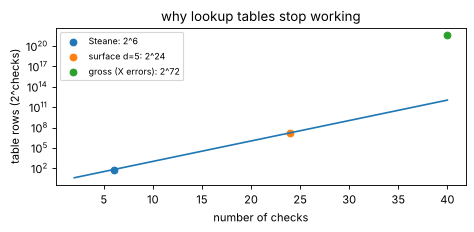

In [2]:
st = steane()
LX, LZ = st.logicals()
dec = LookupDecoder(DecodingProblem.code_capacity(st.HZ, LZ[:, st.n:], 0.01), max_weight=1)
print("Steane table rows:", len(dec), "(7 single errors + no error)")
checks = np.arange(2, 41)
plt.figure(figsize=(6, 3)); plt.semilogy(checks, 2.0 ** checks); plt.xlabel("number of checks"); plt.ylabel("table rows (2^checks)")
for name, m in [("Steane", 6), ("surface d=5", 24), ("gross (X errors)", 72)]:
    plt.scatter([min(m, 40)], [2.0 ** m], label=f"{name}: 2^{m}")
plt.legend(fontsize=8); plt.title("why lookup tables stop working"); plt.tight_layout(); plt.show()

## 2. Matching, drawn on the lattice
Lit checks (stars) get paired along shortest paths (green dashes), and the qubits on those paths are flipped (green rings).
Left: three errors, corrected. Middle: three errors down a column, where going the *other way* is shorter, so we get a logical error.
Right: three errors that are really one, because two of them form a boundary stabilizer.

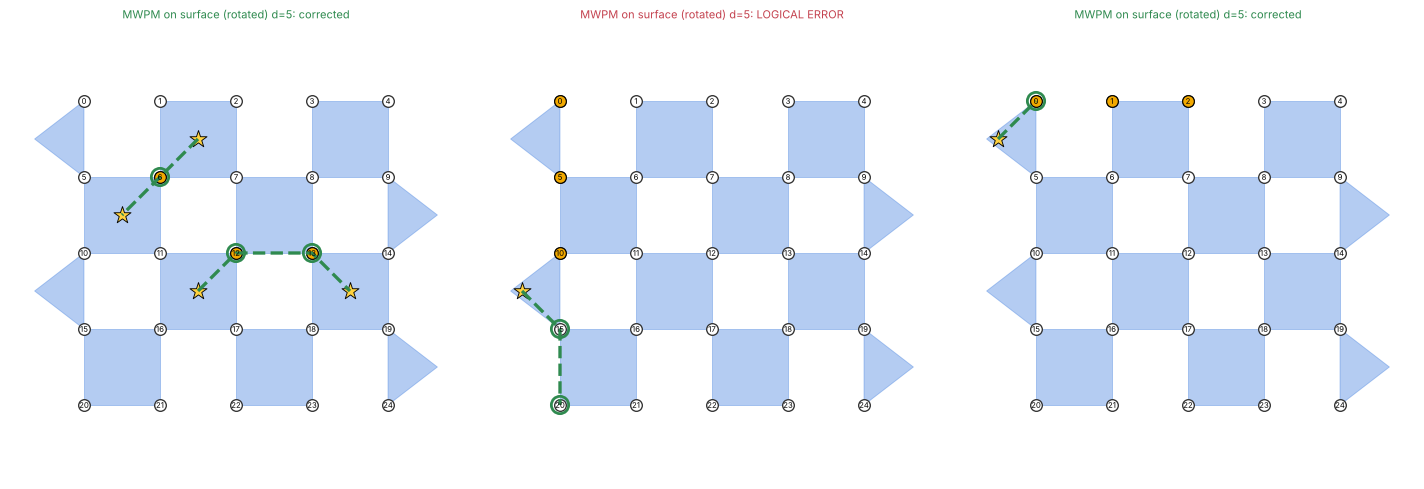

In [3]:
s5 = surface_rotated(5)
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
for ax, qs in zip(axs, [[6, 12, 13], [0, 5, 10], [0, 1, 2]]):
    e = np.zeros(s5.n, np.uint8); e[qs] = 1
    draw_matching(s5, e, ax)
plt.tight_layout(); plt.show()

## 3. Our MWPM vs PyMatching at circuit level
Same circuits, same shots. Ours uses Dijkstra plus exact pairing (bitmask DP for ≤ 20 lit detectors, a small integer program above that).

In [4]:
import pymatching, time
for d, p, shots in [(3, 0.005, 2000), (5, 0.005, 600)]:
    c = memory_circuit(surface_rotated(d), d, p)
    dem = c.detector_error_model(decompose_errors=True, approximate_disjoint_errors=True)
    ours, ref = MWPMDecoder(MatchingGraph(dem)), pymatching.Matching.from_detector_error_model(dem)
    det, obs = c.compile_detector_sampler(seed=1).sample(shots, separate_observables=True)
    t = time.time(); pred = np.array([ours.decode(s) & 1 for s in det]); t = (time.time() - t) / shots
    pm = ref.decode_batch(det)[:, 0]
    print(f"d={d}: same prediction on {np.mean(pred == pm):.2%} of shots | logical error rate ours {np.mean(pred != obs[:,0]):.4f}, "
          f"PyMatching {np.mean(pm != obs[:,0]):.4f} | ours {1e3*t:.1f} ms/shot")

d=3: same prediction on 100.00% of shots | logical error rate ours 0.0670, PyMatching 0.0670 | ours 0.1 ms/shot


d=5: same prediction on 100.00% of shots | logical error rate ours 0.0717, PyMatching 0.0717 | ours 13.6 ms/shot


## 4. A small threshold plot with Sinter, running OUR decoder
`sinter_decoders()` wraps our MWPM so `sinter.collect` can sweep it. Below the threshold, a bigger code is better. We use small shot counts here; increase `max_shots` for smooth curves.

Honest comparison: our circuits do all X checks, then all Z checks, so each round is twice as deep and every idle qubit takes noise in every layer.
That puts the crossing near **0.4%**. Stim's own interleaved circuits with a lighter noise model (no idling noise) cross near 0.5–0.6% (we measured this with PyMatching).
Interleaving the two halves is on the roadmap.

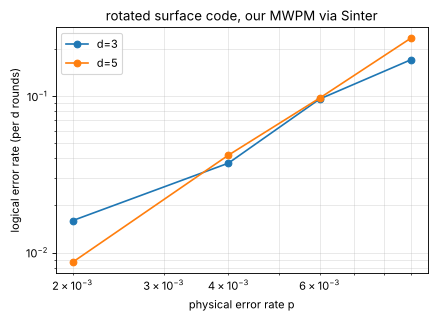

In [5]:
import sinter
tasks = [sinter.Task(circuit=memory_circuit(surface_rotated(d), d, p), json_metadata={"d": d, "p": p})
         for d in (3, 5) for p in (0.002, 0.004, 0.006, 0.009)]
stats = sinter.collect(num_workers=4, tasks=tasks, decoders=["own_mwpm"], custom_decoders=sinter_decoders(),
                       max_shots=1500, max_errors=150)
fig, ax = plt.subplots(figsize=(6, 4))
for d in (3, 5):
    pts = sorted((s.json_metadata["p"], s.errors / s.shots) for s in stats if s.json_metadata["d"] == d)
    ax.plot(*zip(*pts), "o-", label=f"d={d}")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("physical error rate p"); ax.set_ylabel("logical error rate (per d rounds)")
ax.set_title("rotated surface code, our MWPM via Sinter"); ax.grid(alpha=0.3, which="both"); ax.legend(); plt.show()

## 5. BP+OSD on the gross code: what OSD does when BP is stuck
Take a weight-4 error that makes BP oscillate (from notebook 01). OSD ranks qubits by BP's **average** belief, keeps the most reliable independent set (blue),
and solves the syndrome exactly on it. The answer can be a *different* set of qubits from the true error and still be correct, because of degeneracy.

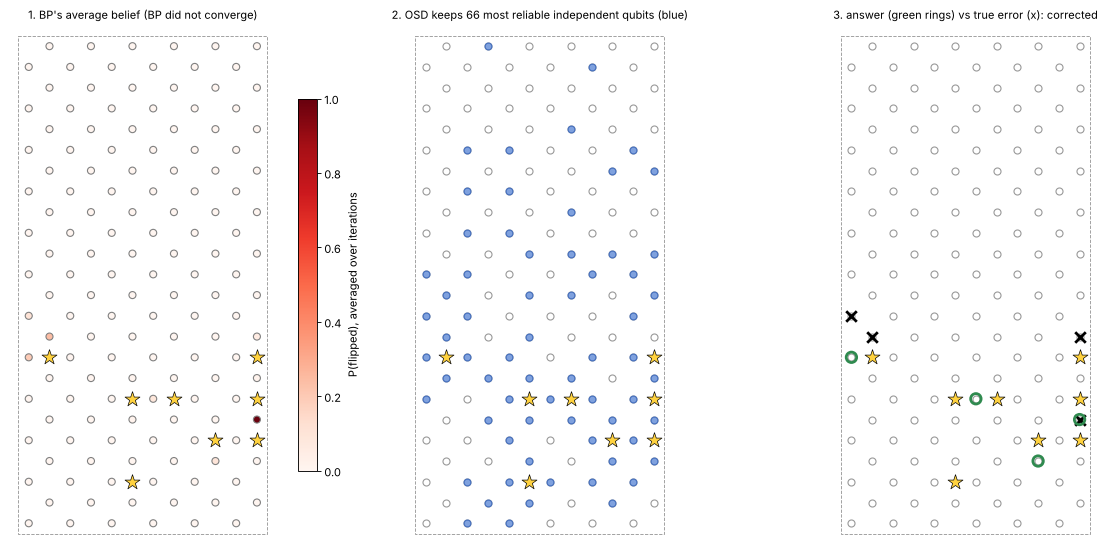

In [6]:
g = bb("gross")
LXg, LZg = g.logicals()
dec = BPOSDDecoder(DecodingProblem.code_capacity(g.HZ, LZg[:, g.n:], 0.03), osd_order=6)
e = np.zeros(g.n, np.uint8); e[[18, 79, 94, 117]] = 1
axs, fail = draw_osd_steps(g, e, dec)
plt.gcf().set_size_inches(16, 7); plt.tight_layout(); plt.show()

## 6. A finding along the way: average beliefs, not the last iteration
When BP oscillates, its last iteration is close to a coin toss. Sorting OSD's qubits by the belief **averaged over all iterations** made our OSD
noticeably better, enough to match or beat `ldpc`'s BP+OSD on the same shots.

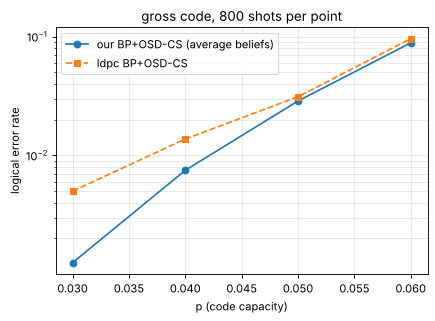

In [7]:
from ldpc import BpOsdDecoder
ps, ours_r, ref_r = [0.03, 0.04, 0.05, 0.06], [], []
H, L = g.HZ, LZg[:, g.n:]
for p in ps:
    ours = BPOSDDecoder(DecodingProblem.code_capacity(H, L, p), osd_order=6)
    ref = BpOsdDecoder(H, error_rate=p, max_iter=50, bp_method="minimum_sum", ms_scaling_factor=0.625, osd_method="osd_cs", osd_order=6)
    fo = fr = 0; N = 800
    for _ in range(N):
        e = (rng.random(g.n) < p).astype(np.uint8); s = (H.astype(int) @ e) % 2; true = (L.astype(int) @ e) % 2
        fo += np.any(ours.decode(s) != true); fr += np.any((L.astype(int) @ ref.decode(s.astype(np.uint8))) % 2 != true)
    ours_r.append(fo / N); ref_r.append(fr / N)
plt.figure(figsize=(6, 4)); plt.plot(ps, ours_r, "o-", label="our BP+OSD-CS (average beliefs)"); plt.plot(ps, ref_r, "s--", label="ldpc BP+OSD-CS")
plt.yscale("log"); plt.xlabel("p (code capacity)"); plt.ylabel("logical error rate"); plt.title("gross code, 800 shots per point")
plt.legend(); plt.grid(alpha=0.3, which="both"); plt.show()

## 7. Where this leaves us
* **lookup**: exact, and dead by about 30 checks
* **MWPM**: ours equals PyMatching shot for shot, but needs a graph
* **BP+OSD**: works on the gross code's hypergraph; ours matches `ldpc`

**Next** (`docs/ARCHITECTURE.md`, roadmap): our own blossom algorithm in place of the integer-program fallback, Union-Find, clustering decoders (LSD, ambiguity clustering),
Relay-BP, BP+OSD at circuit level on the gross code, and Bravyi's depth-8 schedule.